<a href="https://colab.research.google.com/github/Jabbiks/ML/blob/main/%D0%A2%D0%B5%D1%81%D1%82%D0%97%D0%B0%D0%B2%D0%B4_%D0%90%D0%B2%D1%80%D0%B0%D0%BC%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Імпорт бібліотек та завантаження даних

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, RocCurveDisplay
)

# Завантаження набору даних Telco Customer Churn
url_primary = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
url_backup = "https://raw.githubusercontent.com/blastchar/telco-customer-churn/master/WA_Fn-UseC_-Telco-Customer-Churn.csv"

try:
    df = pd.read_csv(url_primary)
except Exception:
    df = pd.read_csv(url_backup)

print("Розмір датасету:", df.shape)
display(df.head())

Розмір датасету: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


2. Розвідувальний аналіз даних (EDA)

In [2]:
# Перегляд структури та типів даних
print("Інформація про стовпці:")
df.info()

# Перевірка на дублікати
print("\nКількість дублікатів:", df.duplicated().sum())

# Стовпець TotalCharges містить пробіли для нових клієнтів — переводимо у числовий формат
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("\nПропущені значення після приведення типів:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nОписова статистика числових ознак:")
display(df.describe())

print("\nРозподіл цільової змінної Churn (%):")
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

Інформація про стовпці:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000



Розподіл цільової змінної Churn (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


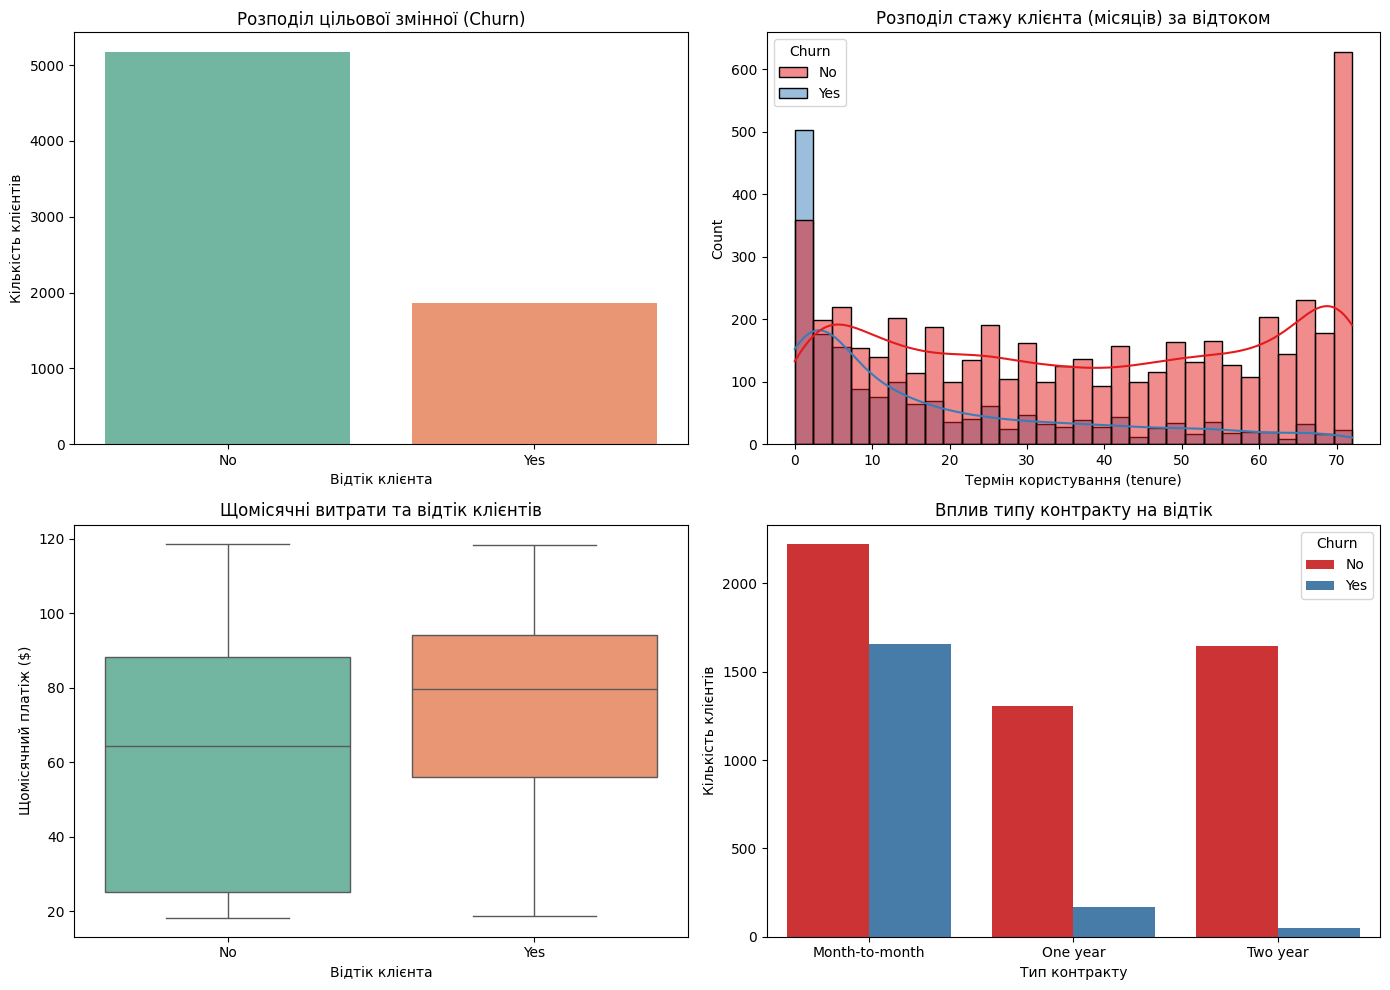

In [3]:
# Візуалізація розподілу цільової змінної та ключових факторів відтоку
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Баланс класів
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Розподіл цільової змінної (Churn)')
axes[0, 0].set_xlabel('Відтік клієнта')
axes[0, 0].set_ylabel('Кількість клієнтів')

# 2. Тривалість користування послугами (tenure)
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=30, palette='Set1', ax=axes[0, 1])
axes[0, 1].set_title('Розподіл стажу клієнта (місяців) за відтоком')
axes[0, 1].set_xlabel('Термін користування (tenure)')

# 3. Щомісячні платежі (MonthlyCharges)
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set2', legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Щомісячні витрати та відтік клієнтів')
axes[1, 0].set_xlabel('Відтік клієнта')
axes[1, 0].set_ylabel('Щомісячний платіж ($)')

# 4. Тип контракту
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set1', ax=axes[1, 1])
axes[1, 1].set_title('Вплив типу контракту на відтік')
axes[1, 1].set_xlabel('Тип контракту')
axes[1, 1].set_ylabel('Кількість клієнтів')

plt.tight_layout()
plt.show()

3. Підготовка даних та побудова конвеєра обробки

In [4]:
# Видаляємо службовий ідентифікатор клієнта
data = df.drop(columns=['customerID']).copy()

# Кодуємо цільову змінну: Yes -> 1 (піде), No -> 0 (залишиться)
X = data.drop(columns=['Churn'])
y = data['Churn'].map({'Yes': 1, 'No': 0})

# Визначаємо числові та категоріальні ознаки
num_features = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [col for col in X.columns if col not in num_features]

print("Числові ознаки:", num_features)
print("Категоріальні ознаки:", cat_features)

# Поділ на навчальну (80%) та тестову (20%) вибірки зі збереженням пропорції класів
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Конвеєр попередньої обробки (без витоку даних)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_features),
        ('cat', categorical_transformer, cat_features)
    ]
)

print(f"\nРозмір навчальної вибірки: {X_train.shape}")
print(f"Розмір тестової вибірки: {X_test.shape}")

Числові ознаки: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Категоріальні ознаки: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Розмір навчальної вибірки: (5634, 19)
Розмір тестової вибірки: (1409, 19)


4. Реалізація та порівняння базових моделей

Порівняння базових моделей на тестовій вибірці:


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Gradient Boosting,0.7991,0.6542,0.5160,0.5770,0.8426
1,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8420
2,Random Forest,0.7921,0.6392,0.4973,0.5594,0.8256
3,SVM (RBF),0.7928,0.6496,0.4759,0.5494,0.7928


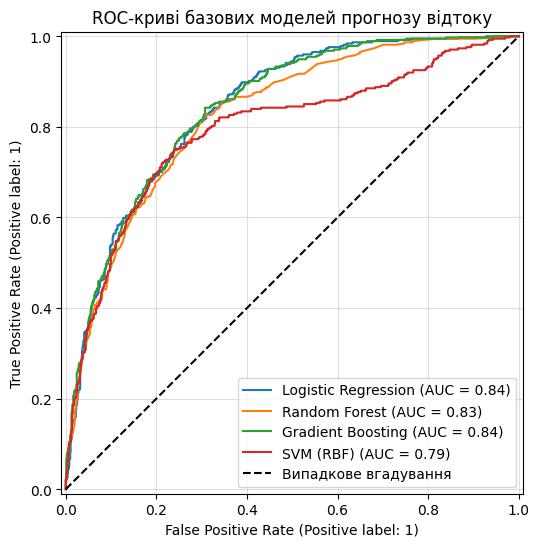

In [5]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'SVM (RBF)': SVC(probability=True, random_state=42)
}

trained_pipelines = {}
comparison_results = []

for name, clf in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    comparison_results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

results_df = pd.DataFrame(comparison_results).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
print("Порівняння базових моделей на тестовій вибірці:")
display(results_df.round(4))

# Графік ROC-кривих для візуального порівняння
fig, ax = plt.subplots(figsize=(8, 6))
for name, pipe in trained_pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)

plt.plot([0, 1], [0, 1], 'k--', label='Випадкове вгадування')
plt.title('ROC-криві базових моделей прогнозу відтоку')
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()

5. Підбір гіперпараметрів та вибір найкращої моделі

Найкращі параметри Gradient Boosting: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
CV ROC-AUC (Gradient Boosting): 0.8493

Найкращі параметри Logistic Regression: {'classifier__C': 10.0}
CV ROC-AUC (Logistic Regression): 0.8463

Результати після підбору гіперпараметрів:


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Tuned Gradient Boosting,0.7984,0.6585,0.5000,0.5684,0.8465
1,Tuned Logistic Regression,0.8048,0.6552,0.5588,0.6032,0.8412



Обрана найкраща модель: Tuned Gradient Boosting

Classification Report:
                precision    recall  f1-score   support

Залишиться (0)       0.83      0.91      0.87      1035
      Піде (1)       0.66      0.50      0.57       374

      accuracy                           0.80      1409
     macro avg       0.75      0.70      0.72      1409
  weighted avg       0.79      0.80      0.79      1409



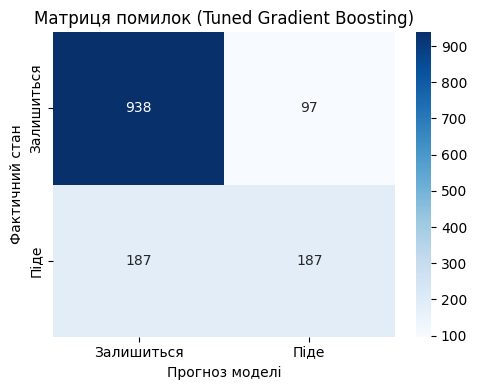

In [6]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. Налаштування параметрів для Gradient Boosting
gb_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

gb_param_grid = {
    'classifier__n_estimators': [100, 150],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__max_depth': [3, 4]
}

grid_gb = GridSearchCV(gb_pipe, gb_param_grid, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
grid_gb.fit(X_train, y_train)

# 2. Налаштування параметрів для Logistic Regression
lr_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

lr_param_grid = {
    'classifier__C': [0.1, 1.0, 10.0]
}

grid_lr = GridSearchCV(lr_pipe, lr_param_grid, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
grid_lr.fit(X_train, y_train)

# Порівняння оптимізованих моделей на тесті
tuned_candidates = {
    'Tuned Gradient Boosting': grid_gb.best_estimator_,
    'Tuned Logistic Regression': grid_lr.best_estimator_
}

print("Найкращі параметри Gradient Boosting:", grid_gb.best_params_)
print(f"CV ROC-AUC (Gradient Boosting): {grid_gb.best_score_:.4f}")
print("\nНайкращі параметри Logistic Regression:", grid_lr.best_params_)
print(f"CV ROC-AUC (Logistic Regression): {grid_lr.best_score_:.4f}")

tuned_rows = []
for name, model in tuned_candidates.items():
    preds = model.predict(X_test)
    probas = model.predict_proba(X_test)[:, 1]
    tuned_rows.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1-score': f1_score(y_test, preds),
        'ROC-AUC': roc_auc_score(y_test, probas)
    })

tuned_df = pd.DataFrame(tuned_rows).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
print("\nРезультати після підбору гіперпараметрів:")
display(tuned_df.round(4))

# Автоматичний вибір найкращої моделі за ROC-AUC
best_model_name = tuned_df.iloc[0]['Модель']
best_model = tuned_candidates[best_model_name]
print(f"\nОбрана найкраща модель: {best_model_name}")

# Детальний звіт та матриця помилок найкращої моделі
y_best_pred = best_model.predict(X_test)
print("\nClassification Report:")
print(classification_report(y_test, y_best_pred, target_names=['Залишиться (0)', 'Піде (1)']))

cm = confusion_matrix(y_test, y_best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Залишиться', 'Піде'],
            yticklabels=['Залишиться', 'Піде'])
plt.title(f'Матриця помилок ({best_model_name})')
plt.xlabel('Прогноз моделі')
plt.ylabel('Фактичний стан')
plt.tight_layout()
plt.show()

6. Прогноз для конкретного клієнта

In [7]:
def predict_client_churn(client_data: dict, model=best_model):
    client_df = pd.DataFrame([client_data])
    prediction = model.predict(client_df)[0]
    churn_prob = model.predict_proba(client_df)[0][1]

    status = "КЛІЄНТ ПІДЕ (високий ризик відтоку)" if prediction == 1 else "КЛІЄНТ ЗАЛИШИТЬСЯ"
    print("=" * 55)
    print(f"Результат прогнозу: {status}")
    print(f"Імовірність відтоку: {churn_prob * 100:.2f}%")
    print(f"Імовірність того, що залишиться: {(1 - churn_prob) * 100:.2f}%")
    print("=" * 55)

# Введення даних клієнта (можна змінювати значення для перевірки різних сценаріїв)
new_client = {
    'gender': 'Female',                    # 'Male' або 'Female'
    'SeniorCitizen': 0,                    # 0 (ні) або 1 (пенсіонер)
    'Partner': 'No',                       # 'Yes' або 'No'
    'Dependents': 'No',                    # 'Yes' або 'No'
    'tenure': 3,                           # Кількість місяців з компанією (0 - 72)
    'PhoneService': 'Yes',                 # 'Yes' або 'No'
    'MultipleLines': 'No',                 # 'Yes', 'No', 'No phone service'
    'InternetService': 'Fiber optic',      # 'DSL', 'Fiber optic', 'No'
    'OnlineSecurity': 'No',                # 'Yes', 'No', 'No internet service'
    'OnlineBackup': 'No',                  # 'Yes', 'No', 'No internet service'
    'DeviceProtection': 'No',              # 'Yes', 'No', 'No internet service'
    'TechSupport': 'No',                   # 'Yes', 'No', 'No internet service'
    'StreamingTV': 'Yes',                  # 'Yes', 'No', 'No internet service'
    'StreamingMovies': 'Yes',              # 'Yes', 'No', 'No internet service'
    'Contract': 'Month-to-month',          # 'Month-to-month', 'One year', 'Two year'
    'PaperlessBilling': 'Yes',             # 'Yes' або 'No'
    'PaymentMethod': 'Electronic check',   # 'Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)'
    'MonthlyCharges': 89.50,               # Щомісячний платіж ($)
    'TotalCharges': 268.50                 # Загальна сума платежів ($)
}

predict_client_churn(new_client)

Результат прогнозу: КЛІЄНТ ПІДЕ (високий ризик відтоку)
Імовірність відтоку: 72.61%
Імовірність того, що залишиться: 27.39%


#Висновки

Для прогнозу відтоку було взято набір даних на 7043 клієнти, де під час перевірки знайшов 11 пропусків у стовпці TotalCharges та нерівномірний розподіл класів (73,5% клієнтів залишаються, а 26,5% йдуть). Перед навчанням моделей я видалив ідентифікатор клієнта, поділив дані на навчальну (5634 записи) та тестову (1409 записів) вибірки, заповнив пропуски й привів усі ознаки до потрібного для алгоритмів вигляду. Серед чотирьох протестованих базових моделей найкраще себе показали градієнтний бустинг та логістична регресія, які дали точність близько 80% і ROC-AUC понад 0,84. Після підбору гіперпараметрів найкращою моделлю став налаштований градієнтний бустинг із показником ROC-AUC 0,8465 на тестовій вибірці. Наприкінці я перевірив роботу цієї моделі на даних нового клієнта і отримав прогноз, що він піде з компанії з імовірністю 72,61%.
